<a href="https://colab.research.google.com/github/Kartikey-Paliwal/dna-gene-family-classifier/blob/main/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("nageshsingh/dna-sequence-dataset")

human = pd.read_table(os.path.join(path, "human.txt"))
chimp = pd.read_table(os.path.join(path, "chimpanzee.txt"))
dog   = pd.read_table(os.path.join(path, "dog.txt"))

print(human.shape)
print(human.head())

100%|██████████| 1.51M/1.51M [00:00<00:00, 121MB/s]

Extracting files...
(4380, 2)


                                            sequence  class
0  ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...      4
1  ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...      4
2  ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...      3
3  ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...      3
4  ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...      3


In [ ]:
seq = human["sequence"][0]
print(len(seq))
print(seq[:100])

207
ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCATACTCCTTACACTATTCCTCATCACCCAACTAAAAATATTAAACACAAACTACC


Day 2: Data Exploration

In [ ]:
class_names = {
    0: "G protein-coupled receptors",
    1: "Tyrosine kinase",
    2: "Tyrosine phosphatase",
    3: "Synthetase",
    4: "Synthase",
    5: "Ion channel",
    6: "Transcription factor"
}

human["family"] = human["class"].map(class_names)
human.head()

,sequence,class,family
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4,Synthase
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4,Synthase
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Synthetase
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3,Synthetase
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3,Synthetase


family
Transcription factor           1343
Synthase                        711
Synthetase                      672
Tyrosine kinase                 534
G protein-coupled receptors     531
Tyrosine phosphatase            349
Ion channel                     240
Name: count, dtype: int64


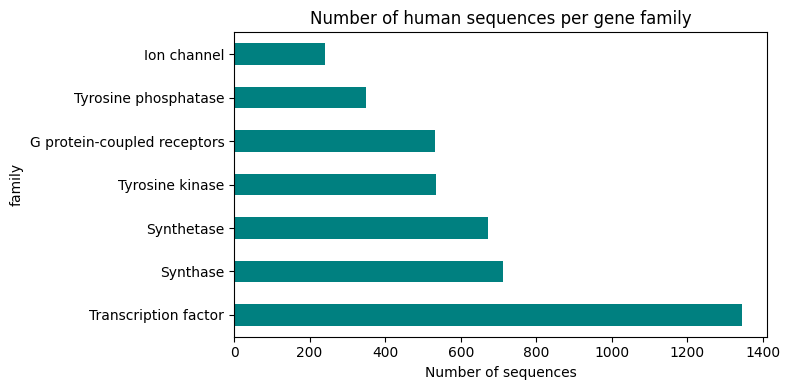

In [ ]:
import matplotlib.pyplot as plt

counts = human["family"].value_counts()
print(counts)

counts.plot(kind="barh", figsize=(8, 4), color="teal")
plt.title("Number of human sequences per gene family")
plt.xlabel("Number of sequences")
plt.tight_layout()
plt.show()

count     4380.000000
mean      1263.598630
std       1280.754087
min          5.000000
25%        405.000000
50%        865.000000
75%       1662.000000
max      18921.000000
Name: length, dtype: float64


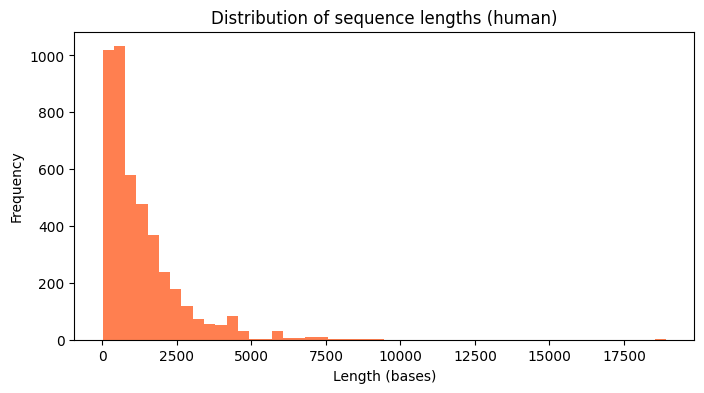

In [ ]:
human["length"] = human["sequence"].str.len()

print(human["length"].describe())

human["length"].plot(kind="hist", bins=50, figsize=(8, 4), color="coral")
plt.title("Distribution of sequence lengths (human)")
plt.xlabel("Length (bases)")
plt.show()

Lengths range from 5 to 18,921; median 865
Distribution is right-skewed (most short, few very long)
Very short sequences may be errors, to be checked
Different lengths are why k-mers are needed

In [ ]:
print(human.groupby("family")["length"].median().sort_values())

family
Synthase                        622.0
Synthetase                      658.5
Transcription factor            870.0
Tyrosine phosphatase            940.0
G protein-coupled receptors    1104.0
Tyrosine kinase                1137.0
Ion channel                    1579.5
Name: length, dtype: float64


                             Human  Chimp    Dog
class                                           
G protein-coupled receptors  0.121  0.139  0.160
Tyrosine kinase              0.122  0.110  0.091
Tyrosine phosphatase         0.080  0.086  0.078
Synthetase                   0.153  0.136  0.116
Synthase                     0.162  0.155  0.165
Ion channel                  0.055  0.065  0.073
Transcription factor         0.307  0.310  0.317


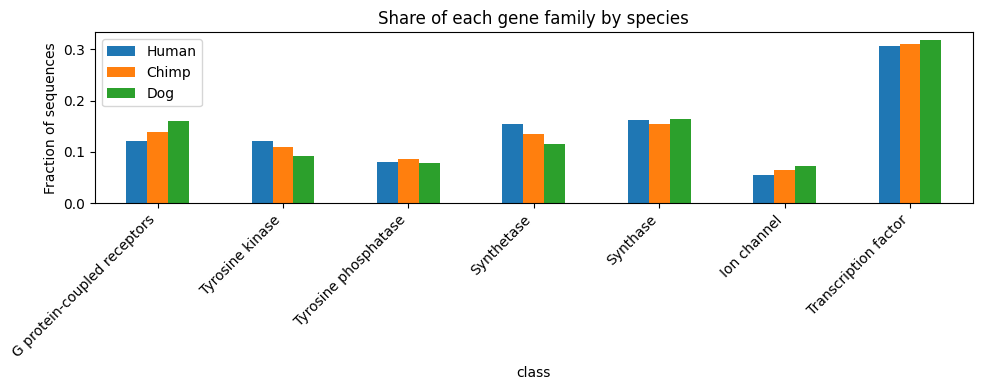

In [ ]:
comparison = pd.DataFrame({
    "Human": human["class"].value_counts(normalize=True),
    "Chimp": chimp["class"].value_counts(normalize=True),
    "Dog":   dog["class"].value_counts(normalize=True),
}).sort_index()

comparison.index = comparison.index.map(class_names)
print(comparison.round(3))

comparison.plot(kind="bar", figsize=(10, 4))
plt.title("Share of each gene family by species")
plt.ylabel("Fraction of sequences")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
dupes = equence").sum()
print("Exact duplicate sequences:", dupes)

Exact duplicate sequences: 751
